# Real-world multi-scale analysis of colorectal cancer H&E

*From H&E slides to tissue contexts, cell neighborhoods and patient-level analyses with ALHENA*

This use case applies ALHENA to two public colorectal cancer cohorts and demonstrates how its tile
embeddings, cell embeddings and cell annotations can be reused across tissue-level, spatial and
patient-level analyses.

Each slide is encoded once. The resulting tile and cell representations, together with the cell
annotations, are stored in scverse-compatible objects and reused throughout the workflow with
Scanpy, SpatialData and Squidpy.

ALHENA is applied to both cohorts as provided, without cohort-specific fitting or calibration.

![Multi-scale view of slide BRAF_094_CT_CBM_P1, from the whole slide to cohort-derived tissue contexts, ALHENA cell annotations and a spatial neighborhood query](../../assets/figures/usecase_hero.webp)

<p class="figure-caption">Overview of the workflow on one example slide. ALHENA tile embeddings are grouped into tissue contexts, cell embeddings receive cell type annotations, and the two scales are combined in a spatial neighborhood query. The outline in panel A marks the region enlarged in panels B to D. Image from BioImage Archive S-BIAD1407, CC BY 4.0.</p>

All quantitative results use complete slides. Smaller regions from `BRAF_094_CT_CBM_P1` are shown
only to make the spatial outputs easier to inspect.

Code blocks show the analysis workflow. Displayed outputs are frozen results from the completed
analysis.

## Cohorts, ALHENA inputs and data from the original study

This example reuses two of the colorectal cancer cohorts described by
[Trahearn et al. (J Pathol, 2025)](https://doi.org/10.1002/path.6378), BRAF and MISSONI, together
with their associated public data resources. H&E slides are available from
[BioImage Archive S-BIAD1407](https://doi.org/10.6019/S-BIAD1407), while nucleus coordinates and
the cell labels reported in the study are available from
[Mendeley Data 9z48yfzr63](https://data.mendeley.com/datasets/9z48yfzr63). Microsatellite
instability (MSI) status is taken from the original publication.

ALHENA receives only the H&E slides and nucleus coordinates. The published cell labels and MSI
status are not used to generate ALHENA embeddings or annotations: the cell labels are introduced
only afterward to compare annotation systems, and MSI status is used only as the outcome for the
patient-level classification analysis.

| Role | Data |
|---|---|
| **Inputs to ALHENA** | H&E slides and nucleus coordinates |
| **Data from the original study used downstream** | Cell labels used to compare ALHENA annotations; MSI status used as the outcome for patient-level classification |

The archive contains 229 primary-tumor slides. After technical quality control for file
integrity and coordinate alignment, 212 slides from 209 patients remain for analysis. No slide is
excluded based on its histological appearance.

The code uses `alhena[spatial,wsi]` and Squidpy 1.8.2 or later.

```python
import numpy as np
import pandas as pd
import spatialdata as sd
import squidpy as sq

import alhena
from alhena import io, spatial
```

In [1]:
# Display helpers of this page, removed from the rendered page. Each frozen output below is shown
# as the notebook shows the object itself: a table by pandas, a text representation as text. The
# two result figures are drawn from their frozen values.
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

COLORS = {"Tumor-containing": "#a8327e"}  # the color of tumor-containing contexts on this page
INK, SECONDARY_INK = "#1f1f1f", "#52514e"
MSI_GROUPS = {  # the two groups of feature blocks in the MSI plot
    "Tissue composition": "Interpretable summaries",
    "Tissue architecture": "Interpretable summaries",
    "Cell composition by tissue context": "Interpretable summaries",
    "Cell spatial features": "Interpretable summaries",
    "Tile codebook": "Representation-level summaries",
    "Mean tumor-tile embedding": "Representation-level summaries",
}


def frozen_table(name):
    """A frozen pandas output, rebuilt exactly from its CSV text."""
    return pd.read_csv(StringIO(FROZEN[name]), index_col=0, float_precision="round_trip")


def show_text(name):
    """Display a frozen text representation as the notebook displays the object itself."""
    display({"text/plain": FROZEN[name].rstrip("\n")}, raw=True)


def plot_msi_results(msi):
    """The MSI plot: AUC with its 95% CI for each feature block, in two groups."""
    msi = msi.assign(group=msi.index.map(MSI_GROUPS))
    figure, ax = plt.subplots(figsize=(8, 3.9))
    ticks, y = [], 0
    for group, block in msi.groupby("group", sort=False):
        ticks.append((y, group, "bold"))
        for row in block.itertuples():
            y += 1
            ax.errorbar(row.auc, y, xerr=[[row.auc - row.ci_low], [row.ci_high - row.auc]],
                        fmt="o", color=INK, capsize=3)
            ax.text(1.01, y, f"{row.auc:.3f} ({row.ci_low:.3f}–{row.ci_high:.3f})", va="center",
                    transform=ax.get_yaxis_transform())
            ticks.append((y, row.Index, "normal"))
        y += 1
    ax.set_yticks([tick for tick, _, _ in ticks], [label for _, label, _ in ticks])
    for label, (_, _, weight) in zip(ax.get_yticklabels(), ticks):
        label.set_fontweight(weight)
    ax.axvline(0.5, color=SECONDARY_INK, linestyle=":", linewidth=1.2)
    ax.set(xlim=(0.35, 1.0), ylim=(y - 0.5, -0.5), xlabel="AUC (95% CI)")
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.show()


def plot_context_agreement(shares):
    """The agreement plot: the share of published lymphocytes ALHENA annotates Immune, by bin."""
    figure, ax = plt.subplots(figsize=(7, 4))
    bins = np.arange(len(shares))
    for scope, color, style in [
        ("Tumor-containing tissue contexts", COLORS["Tumor-containing"], "-"),
        ("Outside tumor-containing tissue contexts", SECONDARY_INK, "--"),
    ]:
        values = shares[scope].to_numpy()
        ax.plot(bins, values, linestyle=style, marker="o", color=color, linewidth=2)
        ax.text(bins[-1] + 0.2, values[-1], scope.replace(" tissue", "\ntissue"), color=color,
                va="center", weight="bold")
    ax.set_xticks(bins, shares.index)
    ax.spines["bottom"].set_bounds(bins[0], bins[-1])
    ax.set(ylim=(0, 1), xlim=(-0.3, len(bins) + 1.2),
           xlabel="Published cancer epithelial cells within 44.65 µm of a published lymphocyte",
           ylabel="Share of published lymphocytes\nthat ALHENA annotates Immune")
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

In [2]:
# Frozen outputs of the code shown on this page, from the completed analysis. Each is displayed
# after the block or expression that produces it; this notebook does not recompute them.
FROZEN = {
    "slide_manifest_head.csv": (
        "slide_id,patient_id,cohort,n_tissue_tiles\n"
        "BRAF/004_AT_PD_P1,BRAF-004,BRAF,44749\n"
        "BRAF/006_AA_CBM_P1,BRAF-006,BRAF,44702\n"
        "BRAF/008_AN_PD_P1,BRAF-008,BRAF,52991\n"
        "BRAF/009_AS_PD_P1,BRAF-009,BRAF,83879\n"
        "BRAF/010_AM_PD_P1,BRAF-010,BRAF,46052\n"
    ),
    "slide_inputs_example.csv": (
        "slide_id,image,tissue_tiles,nuclei\n"
        "BRAF/094_CT_CBM_P1,094_CT_CBM_P1.ome.tif,\"[[97383, 429], [97812, 429], [94809, 858], ...]\",nuclei_input.csv\n"
    ),
    "sdata.txt": (
        "SpatialData object\n"
        "├── Shapes\n"
        "│     ├── 'alhena_tiles': GeoDataFrame shape: (45085, 2) (2D shapes)\n"
        "│     └── 'nuclei': GeoDataFrame shape: (572541, 2) (2D shapes)\n"
        "└── Tables\n"
        "      ├── 'alhena_cells': AnnData (572540, 0)\n"
        "      └── 'alhena_tile_embeddings': AnnData (45085, 0)\n"
        "with coordinate systems:\n"
        "    ▸ 'global', with elements:\n"
        "        alhena_tiles (Shapes), nuclei (Shapes)\n"
    ),
    "tile_table.txt": (
        "AnnData object with n_obs × n_vars = 45085 × 0\n"
        "    obs: 'tile_id', 'alhena_tile_index', 'alhena_tile_x0', 'alhena_tile_y0', 'alhena_tile_x1', 'alhena_tile_y1', 'region'\n"
        "    uns: 'alhena_tiles', 'spatialdata_attrs'\n"
        "    obsm: 'X_alhena_tile', 'spatial'\n"
        "    layers: None (.X)\n"
    ),
    "cell_table.txt": (
        "AnnData object with n_obs × n_vars = 572540 × 0\n"
        "    obs: 'cell_id', 'alhena_tile_index', 'alhena_nucleus_px', 'alhena_n_candidate_tiles', 'alhena_embedding_valid', 'alhena_celltype_compartment_v1', 'alhena_confidence_compartment_v1', 'alhena_valid_compartment_v1', 'alhena_class_entropy_compartment_v1', 'alhena_neighbor_entropy_compartment_v1', 'region'\n"
        "    uns: 'alhena_cells', 'alhena', 'alhena_celltype_compartment_v1_colors', 'spatialdata_attrs'\n"
        "    obsm: 'X_alhena_backbone', 'X_alhena_cell', 'spatial', 'alhena_mass_compartment_v1'\n"
        "    layers: None (.X)\n"
    ),
    "sample_cluster_sizes.csv": (
        "tile_cluster,count\n"
        "TS00,22433\n"
        "TS01,14769\n"
        "TS02,14089\n"
        "TS03,13669\n"
        "TS04,11997\n"
        "TS05,8094\n"
        "TS06,7885\n"
        "TS07,6619\n"
        "TS08,5998\n"
        "TS09,447\n"
    ),
    "assigned_tiles.txt": (
        "7592929\n"
    ),
    "cell_preview.csv": (
        ",compartment,tile_cluster\n"
        "BRAF/094_CT_CBM_P1::0,Immune,TS03\n"
        "BRAF/094_CT_CBM_P1::1,Immune,TS07\n"
        "BRAF/094_CT_CBM_P1::2,Epithelial_Melanocyte,TS07\n"
        "BRAF/094_CT_CBM_P1::3,Immune,TS03\n"
        "BRAF/094_CT_CBM_P1::4,Immune,TS03\n"
    ),
    "per_slide_head.csv": (
        ",slide_id,patient_id,nearby_immune,epithelial_anchors\n"
        "0,BRAF/004_AT_PD_P1,BRAF-004,16947,117166\n"
        "1,BRAF/006_AA_CBM_P1,BRAF-006,84,271\n"
        "2,BRAF/008_AN_PD_P1,BRAF-008,33497,919060\n"
        "3,BRAF/009_AS_PD_P1,BRAF-009,19629,298283\n"
        "4,BRAF/010_AM_PD_P1,BRAF-010,66768,195162\n"
    ),
    "agreement.txt": (
        "73.3% (68,572,514 of 93,518,091 nuclei)\n"
    ),
    "crowding_shares.csv": (
        "published cancer epithelial cells within 44.65 µm,Tumor-containing tissue contexts,Outside tumor-containing tissue contexts\n"
        "0,0.7084231734473861,0.8638435472127377\n"
        "1–2,0.5452157585665574,0.8309990805024877\n"
        "3–5,0.4843868202828362,0.8191105147625013\n"
        "6–10,0.4463719021682977,0.8140664386560788\n"
        "11–20,0.38828940142778695,0.812922282959291\n"
        ">20,0.27816681594875553,0.8232927584072622\n"
    ),
    "tissue_composition_head.csv": (
        "patient_id,share_TS00,share_TS01,share_TS02,share_TS03,share_TS04,share_TS05,share_TS06,share_TS07,share_TS08,share_tumor,share_non_tumor,TS00_in_tumor,TS04_in_tumor,TS05_in_tumor,necrosis_to_tumor,TS01_in_non_tumor,TS02_in_non_tumor,TS03_in_non_tumor,TS06_in_non_tumor,non_tumor_to_tumor\n"
        "BRAF-004,0.293,0.006,0.157,0.076,0.023,0.071,0.153,0.199,0.021,0.386,0.394,0.758,0.059,0.183,0.054,0.016,0.4,0.194,0.39,1.02\n"
        "BRAF-006,0.0,0.373,0.387,0.019,0.004,0.0,0.192,0.002,0.023,0.004,0.971,0.031,0.938,0.031,5.266,0.384,0.398,0.02,0.198,221.604\n"
        "BRAF-008,0.7,0.038,0.024,0.169,0.013,0.045,0.002,0.0,0.008,0.758,0.234,0.923,0.018,0.059,0.01,0.164,0.104,0.721,0.011,0.309\n"
        "BRAF-009,0.144,0.096,0.264,0.418,0.019,0.0,0.033,0.0,0.024,0.163,0.812,0.882,0.117,0.001,0.148,0.119,0.326,0.515,0.041,4.976\n"
        "BRAF-010,0.294,0.047,0.244,0.259,0.018,0.0,0.037,0.011,0.09,0.312,0.587,0.942,0.057,0.001,0.288,0.08,0.416,0.442,0.063,1.88\n"
    ),
    "msi.csv": (
        "block,features,auc,ci_low,ci_high\n"
        "Tissue composition,20,0.5026401446654611,0.423863471971067,0.5809575045207956\n"
        "Tissue architecture,28,0.7960578661844485,0.6994900542495479,0.8799367088607594\n"
        "Cell composition by tissue context,66,0.8010849909584087,0.7079122965641951,0.8758435804701628\n"
        "Cell spatial features,77,0.7555153707052441,0.6572251356238697,0.8409511754068716\n"
        "Tile codebook,32,0.8219891500904157,0.736148282097649,0.8974376130198916\n"
        "Mean tumor-tile embedding,1536,0.9239059674502712,0.8672667269439421,0.9674520795660037\n"
    ),
}

The retained slides are described by `slide_manifest`, one row per slide. `n_tissue_tiles` counts
the 95 µm tiles of a slide that hold at least 25% tissue; ALHENA encodes those tiles.

```python
slide_manifest.head()
```

In [3]:
display(frozen_table("slide_manifest_head.csv"))  # slide_manifest.head()

,patient_id,cohort,n_tissue_tiles
slide_id,,,
BRAF/004_AT_PD_P1,BRAF-004,BRAF,44749
BRAF/006_AA_CBM_P1,BRAF-006,BRAF,44702
BRAF/008_AN_PD_P1,BRAF-008,BRAF,52991
BRAF/009_AS_PD_P1,BRAF-009,BRAF,83879
BRAF/010_AM_PD_P1,BRAF-010,BRAF,46052


## Encode each slide once with ALHENA

`slide_inputs` stores the image input, tissue-tile coordinates and nucleus-coordinate file for
each slide. Each row stores the inputs for one slide.

```python
slide_inputs.loc[
    ["BRAF/094_CT_CBM_P1"],
    ["image", "tissue_tiles", "nuclei"],
]
```

In [4]:
display(frozen_table("slide_inputs_example.csv"))  # the example slide's entry of slide_inputs

,image,tissue_tiles,nuclei
slide_id,,,
BRAF/094_CT_CBM_P1,094_CT_CBM_P1.ome.tif,"[[97383, 429], [97812, 429], [94809, 858], ...]",nuclei_input.csv


ALHENA encodes one slide at a time. The analysis applied this per-slide workflow across the
cohort and kept the 212 slides that passed technical quality control for downstream analyses.
Below we show the ALHENA workflow applied to the slide `BRAF_094_CT_CBM_P1` as an example.

`encode_cells(..., all_tiles=True)` produces the cell representations and keeps the tile
representations from the same image encoding. `compartment_v1` then annotates the stored cell
embeddings without re-encoding the H&E image.

The public dataset provides nucleus centroids rather than nucleus outlines. Here each centroid is
represented by a 3.5 µm-radius disk before cell encoding. See
[Centroids](../../inputs/nuclei/#centroids) for the centroid representation.

```python
MPP = 2 * 0.11112244784568931  # microns per slide pixel
NUCLEUS_RADIUS_PX = round(3.5 / MPP)

encoder = alhena.load_encoder()
compartment_typer = alhena.load_celltyper(tissue="Colon", axis="compartment_v1")

slide = slide_inputs.loc["BRAF/094_CT_CBM_P1"]

with io.read_slide(
    slide["image"],
    mpp=MPP,
    coords=slide["tissue_tiles"],
) as source:
    nuclei = io.read_centroids(
        slide["nuclei"],
        tiles=source,
        frame="origins",
        radius_px=NUCLEUS_RADIUS_PX,
    )
    cells = encoder.encode_cells(source, nuclei, all_tiles=True)

compartments = compartment_typer.annotate(cells)
```

The tile and cell tables are placed together with the nucleus geometry in a SpatialData object
for the spatial analysis.

```python
from spatialdata.models import ShapesModel

nucleus_coordinates = pd.read_csv(slide["nuclei"])
sdata = sd.SpatialData(
    shapes={
        "nuclei": ShapesModel.parse(
            nucleus_coordinates[["x", "y"]].to_numpy(),
            geometry=0,
            radius=float(NUCLEUS_RADIUS_PX),
            index=nucleus_coordinates["cell_id"],
        )
    }
)

spatial.tiles_to_spatialdata(sdata, cells.tiles)
spatial.cells_to_spatialdata(sdata, compartments, region="nuclei")
```

```python
sdata
```

In [5]:
show_text("sdata.txt")  # sdata

SpatialData object
├── Shapes
│     ├── 'alhena_tiles': GeoDataFrame shape: (45085, 2) (2D shapes)
│     └── 'nuclei': GeoDataFrame shape: (572541, 2) (2D shapes)
└── Tables
      ├── 'alhena_cells': AnnData (572540, 0)
      └── 'alhena_tile_embeddings': AnnData (45085, 0)
with coordinate systems:
    ▸ 'global', with elements:
        alhena_tiles (Shapes), nuclei (Shapes)

```python
sdata.tables["alhena_tile_embeddings"]
```

In [6]:
show_text("tile_table.txt")  # sdata.tables["alhena_tile_embeddings"]

AnnData object with n_obs × n_vars = 45085 × 0
    obs: 'tile_id', 'alhena_tile_index', 'alhena_tile_x0', 'alhena_tile_y0', 'alhena_tile_x1', 'alhena_tile_y1', 'region'
    uns: 'alhena_tiles', 'spatialdata_attrs'
    obsm: 'X_alhena_tile', 'spatial'
    layers: None (.X)

```python
sdata.tables["alhena_cells"]
```

In [7]:
show_text("cell_table.txt")  # sdata.tables["alhena_cells"]

AnnData object with n_obs × n_vars = 572540 × 0
    obs: 'cell_id', 'alhena_tile_index', 'alhena_nucleus_px', 'alhena_n_candidate_tiles', 'alhena_embedding_valid', 'alhena_celltype_compartment_v1', 'alhena_confidence_compartment_v1', 'alhena_valid_compartment_v1', 'alhena_class_entropy_compartment_v1', 'alhena_neighbor_entropy_compartment_v1', 'region'
    uns: 'alhena_cells', 'alhena', 'alhena_celltype_compartment_v1_colors', 'spatialdata_attrs'
    obsm: 'X_alhena_backbone', 'X_alhena_cell', 'spatial', 'alhena_mass_compartment_v1'
    layers: None (.X)

The `nuclei` element holds 572,541 nucleus shapes and the cell table 572,540 cells: one nucleus
has no overlapping image token and therefore has no encoded cell representation.

The tile embeddings are in `obsm["X_alhena_tile"]` of the tile table, while the cell embeddings
and the `compartment_v1` annotations are stored directly in the cell table.

From this point on, the analysis reuses these stored outputs rather than re-encoding the H&E
image. The same per-slide outputs are available for each of the 212 retained slides: below,
`sdatas[slide_id]` is a slide's SpatialData object, and `tile_tables[slide_id]` and
`cell_tables[slide_id]` are its two tables.

## Turn tile embeddings into tissue contexts

ALHENA provides one embedding for every tissue tile. To organize these embeddings into recurring
tissue contexts, we fit the clustering used below across the analyzed cohort. This clustering is a
downstream analysis of ALHENA outputs rather than a component of ALHENA itself.

This provides a tissue-level view of the slides that can later be combined with the cell-level
outputs. The clustering runs on up to 500 tiles from each slide.

```python
import zlib

import anndata as ad
import scanpy as sc
from sklearn.decomposition import PCA


def draw(slide_id, n_tiles):
    """Up to 500 tissue tiles of one slide, with one fixed seed per slide."""
    rng = np.random.default_rng([0, zlib.crc32(slide_id.encode())])
    return np.sort(rng.choice(n_tiles, size=min(n_tiles, 500), replace=False))


def l2(X):
    """Scale every row to unit length."""
    return X / np.linalg.norm(X, axis=1, keepdims=True)


sampled_tiles = ad.concat(
    [tiles[draw(slide_id, tiles.n_obs)] for slide_id, tiles in tile_tables.items()]
)
X = l2(sampled_tiles.obsm["X_alhena_tile"])
sample = ad.AnnData(
    PCA(n_components=50, svd_solver="covariance_eigh", random_state=0).fit_transform(X)
)
sc.pp.neighbors(sample, n_neighbors=15, use_rep="X", transformer="sklearn")  # exact neighbors
sc.tl.leiden(sample, resolution=0.3, flavor="igraph", n_iterations=2, key_added="tile_cluster")

sizes = sample.obs["tile_cluster"].value_counts()  # Leiden's labels; TS00 is the largest cluster
sample.obs["tile_cluster"] = sample.obs["tile_cluster"].map(
    {label: f"TS{i:02d}" for i, label in enumerate(sizes.index)}
)
```

```python
sample.obs["tile_cluster"].value_counts()
```

In [8]:
display(frozen_table("sample_cluster_sizes.csv")["count"])  # value_counts() of the sample

tile_cluster
TS00    22433
TS01    14769
TS02    14089
TS03    13669
TS04    11997
TS05     8094
TS06     7885
TS07     6619
TS08     5998
TS09      447
Name: count, dtype: int64

One centroid is calculated per cluster, and every tissue tile in the cohort is assigned to its
nearest centroid by cosine similarity.

```python
clusters = sorted(sample.obs["tile_cluster"].unique())
centroids = l2(np.stack([
    X[(sample.obs["tile_cluster"] == cluster).to_numpy()].mean(axis=0, dtype=np.float64)
    for cluster in clusters
]))
for tiles in tile_tables.values():  # every tissue tile of the cohort
    similarity = l2(tiles.obsm["X_alhena_tile"]) @ centroids.T  # cosine to each centroid
    tiles.obs["tile_cluster"] = np.asarray(clusters)[similarity.argmax(axis=1)]
```

```python
sum(tiles.n_obs for tiles in tile_tables.values())
```

In [9]:
show_text("assigned_tiles.txt")  # the tiles of the cohort's tile tables

7592929

All 7,592,929 tissue tiles are assigned to one of the ten TS clusters.

The ten TS clusters are unsupervised groups of tile embeddings. They are grouped into five
descriptive tissue contexts.

```python
CONTEXT = {
    "TS00": "Tumor-containing",
    "TS04": "Tumor-containing",
    "TS05": "Tumor-containing",
    "TS01": "Non-tumor tissue",
    "TS02": "Non-tumor tissue",
    "TS03": "Non-tumor tissue",
    "TS06": "Non-tumor tissue",
    "TS07": "Normal mucosa",
    "TS08": "Necrosis",
    "TS09": "Artifact or background",
}
```

The context names are descriptive. They were assigned from H&E appearance and ALHENA cell type
composition without using the published cell labels.

![Cohort tile clusters on slide BRAF_094_CT_CBM_P1 grouped into tissue contexts, with the displayed region outlined and three H&E tiles for each context](../../assets/figures/usecase_tissue_contexts.webp)

<p class="figure-caption">Cohort-derived tissue contexts on <code>BRAF_094_CT_CBM_P1</code>. The outlined region corresponds to the region enlarged in the overview figure. Example tiles were selected near their cluster centroids to show the morphology associated with each tissue context. Image from S-BIAD1407, CC BY 4.0.</p>

## Connect tissue context to cell annotations

Every encoded cell keeps the index of the tissue tile from which it was generated. The
cohort-derived tissue context can therefore be attached directly to each cell.

```python
for slide_id, cell_table in cell_tables.items():
    tile_cluster = (
        tile_tables[slide_id]
        .obs
        .set_index("alhena_tile_index")["tile_cluster"]
    )
    cell_table.obs["tile_cluster"] = (
        cell_table.obs["alhena_tile_index"].map(tile_cluster)
    )
    cell_table.obs["compartment"] = cell_table.obs[
        "alhena_celltype_compartment_v1"
    ].where(cell_table.obs["alhena_valid_compartment_v1"])
```

```python
EXAMPLE_SLIDE = "BRAF/094_CT_CBM_P1"

cell_tables[EXAMPLE_SLIDE].obs[
    ["compartment", "tile_cluster"]
].head()
```

In [10]:
display(frozen_table("cell_preview.csv"))  # the first cells of the example slide

,compartment,tile_cluster
BRAF/094_CT_CBM_P1::0,Immune,TS03
BRAF/094_CT_CBM_P1::1,Immune,TS07
BRAF/094_CT_CBM_P1::2,Epithelial_Melanocyte,TS07
BRAF/094_CT_CBM_P1::3,Immune,TS03
BRAF/094_CT_CBM_P1::4,Immune,TS03


Cell-level annotations and tissue-level context can now be used together.

Because the nuclei and ALHENA tables share the same SpatialData coordinate system, both scales
can be inspected in the same field.

```python
EXAMPLE_FIELD_MIN = [87087, 9867]
EXAMPLE_FIELD_MAX = [93093, 15873]

example_sdata = sdatas[EXAMPLE_SLIDE]

field = sd.bounding_box_query(
    example_sdata,
    axes=("x", "y"),
    min_coordinate=EXAMPLE_FIELD_MIN,
    max_coordinate=EXAMPLE_FIELD_MAX,
    target_coordinate_system="global",
    filter_table=True,
)
```

![A field of slide BRAF_094_CT_CBM_P1 shown twice, with its cohort-derived tissue contexts and with its ALHENA compartment_v1 annotations](../../assets/figures/usecase_field.webp)

<p class="figure-caption">The same field shown with cohort-derived tissue contexts and ALHENA <code>compartment_v1</code> annotations. Both are queried from the same SpatialData coordinate system. Image from S-BIAD1407, CC BY 4.0.</p>

## Query tumor-immune neighborhoods with Squidpy

Tissue context, cell annotation and coordinates can now be combined in one spatial question.
Which Immune cells lie within the neighborhood of epithelial cells in tumor-containing tissue?

The neighborhood radius is set to approximately 44.65 µm, matching the distance threshold used in
the published study.

```python
SCALE = 2.009  # slide pixels per pixel of the published nucleus coordinates
NEIGHBORHOOD_RADIUS_PX = np.nextafter(100 * SCALE, 0.0)  # 100 published pixels, about 44.65 µm

TUMOR_CLUSTERS = ["TS00", "TS04", "TS05"]  # tumor-containing tissue contexts
NON_COUNTED_CLUSTERS = ["TS07", "TS08", "TS09"]  # normal mucosa, necrosis, artifact or background
```

`epithelial_anchors` counts the valid epithelial annotations on tumor-containing tiles.
`nearby_immune` counts the valid Immune annotations within 44.65 µm of at least one of those
anchors. Immune cells in normal mucosa, necrosis or artifact/background are not included in the
neighborhood count.

```python
rows = []

for slide_id, cell_table in cell_tables.items():
    obs = cell_table.obs
    tumor = obs["tile_cluster"].isin(TUMOR_CLUSTERS)
    non_counted_tissue = obs["tile_cluster"].isin(NON_COUNTED_CLUSTERS)

    obs["anchor"] = obs["compartment"].eq("Epithelial_Melanocyte") & tumor
    obs["eligible_immune"] = obs["compartment"].eq("Immune") & ~non_counted_tissue

    sq.gr.spatial_neighbors_radius(
        cell_table, radius=NEIGHBORHOOD_RADIUS_PX, key_added="neighborhood"
    )
    graph = cell_table.obsp["neighborhood_connectivities"]
    obs["near_anchor"] = (
        np.asarray(graph[:, obs["anchor"].to_numpy()].sum(axis=1)).ravel() > 0
    )
    obs["counted"] = obs["eligible_immune"] & obs["near_anchor"]

    rows.append(
        {
            "slide_id": slide_id,
            "patient_id": slide_manifest.loc[slide_id, "patient_id"],
            "nearby_immune": int(obs["counted"].sum()),
            "epithelial_anchors": int(obs["anchor"].sum()),
        }
    )

per_slide = pd.DataFrame(rows)
```

```python
per_slide.head()
```

In [11]:
display(frozen_table("per_slide_head.csv"))  # per_slide.head()

,slide_id,patient_id,nearby_immune,epithelial_anchors
0,BRAF/004_AT_PD_P1,BRAF-004,16947,117166
1,BRAF/006_AA_CBM_P1,BRAF-006,84,271
2,BRAF/008_AN_PD_P1,BRAF-008,33497,919060
3,BRAF/009_AS_PD_P1,BRAF-009,19629,298283
4,BRAF/010_AM_PD_P1,BRAF-010,66768,195162


The figure below reads these cell-level flags in a 0.5 mm crop of the example slide.

```python
NEIGHBORHOOD_CROP = (86009, 11468, 2250)  # x, y, side in full-slide pixels

x0, y0, side = NEIGHBORHOOD_CROP

neighborhood_view = sd.bounding_box_query(
    sdatas[EXAMPLE_SLIDE],
    axes=("x", "y"),
    min_coordinate=[x0, y0],
    max_coordinate=[x0 + side, y0 + side],
    target_coordinate_system="global",
    filter_table=True,
)
```

<img src="../../assets/figures/usecase_neighborhood.webp" width="430" alt="A 0.5 mm crop of slide BRAF_094_CT_CBM_P1 with the epithelial anchors, the Immune annotations counted within 44.65 µm, those beyond it, and those in normal mucosa, necrosis or artifact/background">

<p class="figure-caption">Example crop showing epithelial anchors and Immune cells classified by the spatial query above. Filled blue points are counted in <code>nearby_immune</code>. Open blue points are eligible Immune cells outside the 44.65 µm neighborhood. Crosses mark Immune cells in normal mucosa, necrosis or artifact/background, which are not included in the neighborhood count. The dashed circle marks the 44.65 µm neighborhood of one anchor. Image from S-BIAD1407, CC BY 4.0.</p>

## Where ALHENA and the published labels disagree

The published cell labels have not been used by ALHENA in any of the analyses above. They are
introduced here only to compare the ALHENA annotations with the annotations reported for these
cohorts in the original publication.

`published_labels[slide_id]` holds the published table of a slide: one row per published
nucleus, indexed by cell ID, with its class (`published_class`) and its position in the
published pixels (`x_pub`, `y_pub`). The eight published classes are mapped to the three
`compartment_v1` cell types.

```python
PUBLISHED_COMPARTMENT = {
    "cep": "Epithelial_Melanocyte",
    "nep": "Epithelial_Melanocyte",
    "lym": "Immune",
    "mac": "Immune",
    "neu": "Immune",
    "fib": "Stromal_Vascular",
    "end": "Stromal_Vascular",
    "myo": "Stromal_Vascular",
}

labeled_slides = [
    cell_table.obs[["compartment", "tile_cluster"]]
    .dropna(subset=["compartment"])  # valid annotations only
    .join(published_labels[slide_id], how="inner")
    for slide_id, cell_table in cell_tables.items()
]
labeled = pd.concat(labeled_slides)
agreement = labeled["published_class"].map(PUBLISHED_COMPARTMENT).eq(labeled["compartment"])
print(f"{agreement.mean():.1%} ({agreement.sum():,} of {len(agreement):,} nuclei)")
```

In [12]:
print(FROZEN["agreement.txt"], end="")  # the line the agreement block prints

73.3% (68,572,514 of 93,518,091 nuclei)


Because the published labels are themselves inferred from H&E, the 73.3% value should be
interpreted as agreement between two H&E-based annotation systems.

ALHENA cell embeddings include information from the surrounding tissue. The next comparison asks
whether agreement with the published labels changes as a published lymphocyte is surrounded by
increasing numbers of published cancer epithelial cells.

```python
from scipy.spatial import cKDTree


def crowding(labeled):
    """A slide's published lymphocytes, with the published cancer epithelial cells near each."""
    lymphocytes = labeled[labeled["published_class"] == "lym"]
    cancer_epithelial = labeled.loc[labeled["published_class"] == "cep", ["x_pub", "y_pub"]]
    n_cep = cKDTree(cancer_epithelial).query_ball_point(
        lymphocytes[["x_pub", "y_pub"]], r=np.nextafter(100.0, 0.0), return_length=True
    )  # strictly within 100 published pixels, about 44.65 µm
    return lymphocytes.assign(n_cep=n_cep)


lymphocytes = pd.concat([crowding(labeled) for labeled in labeled_slides])
bins = pd.cut(lymphocytes["n_cep"], [-1, 0, 2, 5, 10, 20, np.inf],
              labels=["0", "1–2", "3–5", "6–10", "11–20", ">20"])
in_tumor = lymphocytes["tile_cluster"].isin(TUMOR_CLUSTERS)
share_immune = lymphocytes["compartment"].eq("Immune").groupby([in_tumor, bins]).mean()
```

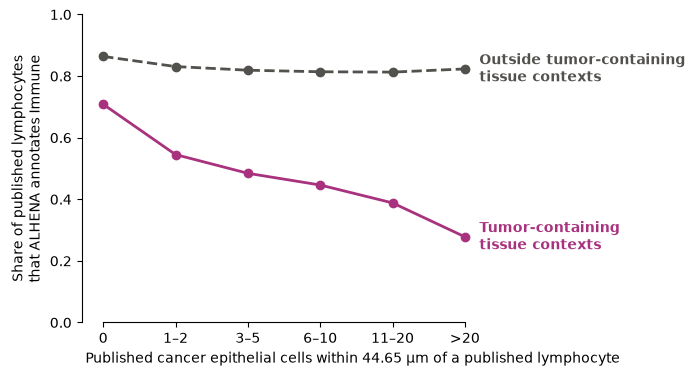

In [13]:
plot_context_agreement(frozen_table("crowding_shares.csv"))  # share_immune, by bin

<p class="figure-caption">Share of published lymphocytes that ALHENA annotates Immune, by the number of published cancer epithelial cells within 44.65 µm, inside and outside tumor-containing tissue, across the cohort.</p>

Outside tumor-containing tissue, agreement remains around 81 to 86%. Within tumor-containing
tissue, agreement decreases as the number of nearby published cancer epithelial cells increases,
from 70.8% with none nearby to 27.8% with more than 20.

The quantitative result shows where disagreement is most frequent. The images below let the
reader inspect what those regions look like.

<img src="../../assets/figures/usecase_triptych.webp" width="592" alt="Three fields of slide BRAF_094_CT_CBM_P1, each shown as H&amp;E, with ALHENA compartment_v1 annotations and with the published labels mapped to the same cell type classes">

<p class="figure-caption">Three 200 µm fields centered on published lymphocytes with more than 20 published cancer epithelial cells within 44.65 µm in tumor-containing tissue. Each row shows the same field as H&amp;E alone, with ALHENA <code>compartment_v1</code> annotations, and with the published labels mapped to the same broad cell type classes. The target nucleus is marked in every panel. Image from S-BIAD1407, CC BY 4.0; published labels from Mendeley Data 9z48yfzr63, CC BY 4.0.</p>

These examples show that disagreements can arise in morphologically complex tumor regions, where
nuclei labeled as lymphocytes in the published annotations can lie among many nearby epithelial
cells.

## From slides to patients

So far, the analysis has stayed at tile and cell level. To move to the patient level, outputs from
all available slides belonging to the same patient are pooled and summarized. This produces one
feature vector per patient rather than one observation per tile or cell.

When a patient has multiple slides, counts are summed across slides before proportions, ratios or
densities are calculated; slide-level values are not averaged. Spatial relationships, such as tile
adjacency or cell neighborhoods, are first evaluated within each slide and their counts are then
combined across the patient.

### Tissue composition

A simple patient-level summary is tissue composition. For each patient, we pool all tissue tiles
from all available slides and count how many belong to each tile cluster. TS09 (artifact or
background) is left out, so tissue refers here to TS00–TS08.

The resulting features describe both the overall abundance of individual tile clusters and their
composition within broader groups. For example:

- `share_TS04` is the number of TS04 tiles divided by all tissue tiles from the patient.
- `share_tumor` is the number of tiles in the tumor-containing clusters TS00, TS04 and TS05
  divided by all tissue tiles.
- `share_non_tumor` is the corresponding fraction for TS01, TS02, TS03 and TS06.
- `TS04_in_tumor` is the number of TS04 tiles divided by all tumor-containing tiles.
- `TS02_in_non_tumor` is the number of TS02 tiles divided by all non-tumor tissue tiles.
- `necrosis_to_tumor` is the number of TS08 tiles divided by the number of tumor-containing tiles.
- `non_tumor_to_tumor` is the number of non-tumor tissue tiles divided by the number of
  tumor-containing tiles.

These definitions produce 18 proportions and two ratios. Unlike the proportions, the two ratios
can exceed 1 when the numerator contains more tiles than the denominator.

```python
for slide_id, tiles in tile_tables.items():
    tiles.obs["patient_id"] = slide_manifest.loc[slide_id, "patient_id"]

cohort_tiles = pd.concat([tiles.obs for tiles in tile_tables.values()], ignore_index=True)
tissue = cohort_tiles[cohort_tiles["tile_cluster"] != "TS09"]  # artifact or background left out
per_cluster = pd.crosstab(tissue["patient_id"], tissue["tile_cluster"])  # tiles per patient

NON_TUMOR_CLUSTERS = ["TS01", "TS02", "TS03", "TS06"]
n_tissue = per_cluster.sum(axis=1)
n_tumor = per_cluster[TUMOR_CLUSTERS].sum(axis=1)
n_non_tumor = per_cluster[NON_TUMOR_CLUSTERS].sum(axis=1)

tissue_composition = pd.concat(
    [
        per_cluster.div(n_tissue, axis=0).add_prefix("share_"),
        (n_tumor / n_tissue).rename("share_tumor"),
        (n_non_tumor / n_tissue).rename("share_non_tumor"),
        per_cluster[TUMOR_CLUSTERS].div(n_tumor, axis=0).add_suffix("_in_tumor"),
        (per_cluster["TS08"] / n_tumor).rename("necrosis_to_tumor"),
        per_cluster[NON_TUMOR_CLUSTERS].div(n_non_tumor, axis=0).add_suffix("_in_non_tumor"),
        (n_non_tumor / n_tumor).rename("non_tumor_to_tumor"),
    ],
    axis=1,
)
```

```python
tissue_composition.head().round(3)
```

In [14]:
display(frozen_table("tissue_composition_head.csv"))  # tissue_composition.head().round(3)

,share_TS00,share_TS01,share_TS02,share_TS03,share_TS04,share_TS05,share_TS06,share_TS07,share_TS08,share_tumor,share_non_tumor,TS00_in_tumor,TS04_in_tumor,TS05_in_tumor,necrosis_to_tumor,TS01_in_non_tumor,TS02_in_non_tumor,TS03_in_non_tumor,TS06_in_non_tumor,non_tumor_to_tumor
patient_id,,,,,,,,,,,,,,,,,,,,
BRAF-004,0.293,0.006,0.157,0.076,0.023,0.071,0.153,0.199,0.021,0.386,0.394,0.758,0.059,0.183,0.054,0.016,0.400,0.194,0.390,1.020
BRAF-006,0.000,0.373,0.387,0.019,0.004,0.000,0.192,0.002,0.023,0.004,0.971,0.031,0.938,0.031,5.266,0.384,0.398,0.020,0.198,221.604
BRAF-008,0.700,0.038,0.024,0.169,0.013,0.045,0.002,0.000,0.008,0.758,0.234,0.923,0.018,0.059,0.010,0.164,0.104,0.721,0.011,0.309
BRAF-009,0.144,0.096,0.264,0.418,0.019,0.000,0.033,0.000,0.024,0.163,0.812,0.882,0.117,0.001,0.148,0.119,0.326,0.515,0.041,4.976
BRAF-010,0.294,0.047,0.244,0.259,0.018,0.000,0.037,0.011,0.090,0.312,0.587,0.942,0.057,0.001,0.288,0.080,0.416,0.442,0.063,1.880


Each row now represents one patient rather than one tile or slide.

### Other patient-level summaries

Tissue composition is only one way to aggregate the stored ALHENA outputs. For the downstream
analysis below, we construct six complementary patient-level feature blocks that retain different
aspects of tissue composition, tissue organization, cell phenotypes, spatial organization or the
learned tile representations.

| Feature block | What is summarized for each patient | Features |
|---|---|---:|
| Tissue composition | Relative abundance of individual tile clusters, composition within the tumor-containing and non-tumor groups, and ratios between selected tissue contexts | 20 |
| Tissue architecture | Shape and organization of tumor-containing tissue, together with adjacency patterns between tile clusters | 28 |
| Cell composition by tissue context | ALHENA epithelial, Immune and stromal cell composition and density across tissue regions, together with Immune heterogeneity within tumor-containing tissue | 66 |
| Cell spatial features | Local relationships between ALHENA-annotated cell types, including nearest-cell distances, neighborhood composition and Immune aggregates | 77 |
| Tile codebook | Distribution of the patient's tissue tiles across 32 clusters in ALHENA tile-embedding space | 32 |
| Mean tumor-tile embedding | Mean 1536-dimensional ALHENA tile embedding across the patient's tumor-containing tiles | 1536 |

The **28 tissue-architecture features** use the tile-cluster assignment and grid position of each
tile. Seven features describe properties of the tumor-containing regions, including their edge
fraction, depth, fragmentation and contact with surrounding tissue or necrosis. The other 21
measure whether selected pairs of tile clusters are adjacent more or less often than expected
from their abundance.

The **66 cell-composition features** summarize ALHENA epithelial, Immune and stromal annotations
across 13 tissue regions, including tumor-containing tissue, individual tumor clusters, tumor edge
and core, and non-tumor regions at increasing distances from tumor. They include cell-type
fractions, total and Immune cell densities, and measures of how unevenly Immune cells are
distributed across tumor-containing tiles.

The **77 cell-spatial features** use the coordinates and ALHENA cell type of each cell to
describe local cellular organization. They summarize, across several tissue regions, how often
Immune cells lie close to epithelial or stromal cells, how cell types are represented among
the ten nearest neighbors of each cell, and whether epithelial cells occur in isolated or
stromal-rich neighborhoods. Additional features describe Immune-cell aggregates and their
relationship to tumor-containing tissue.

The **tile codebook** provides a compact summary of the ALHENA tile embeddings without averaging
them into a single vector. The tile-embedding space is first reduced by PCA and then divided into
32 clusters using k-means; the 32 cluster centers together form the codebook. Each tissue tile is
assigned to its nearest cluster. For each patient, we calculate the fraction of tissue tiles
assigned to each of the 32 clusters. These 32 values sum to 1 and describe how the patient's
tissue is distributed across recurring patterns in ALHENA embedding space.

At the other end of the representation spectrum, the **mean tumor-tile embedding** retains
ALHENA's full 1536-dimensional representation. For each patient, tile embeddings are averaged
across all tiles belonging to the tumor-containing clusters TS00, TS04 and TS05.

```python
sums = {}
counts = {}

for tiles in tile_tables.values():
    patient = tiles.obs["patient_id"].iloc[0]
    tumor = tiles[tiles.obs["tile_cluster"].isin(TUMOR_CLUSTERS)]

    sums[patient] = sums.get(patient, 0) + tumor.obsm["X_alhena_tile"].sum(axis=0)
    counts[patient] = counts.get(patient, 0) + tumor.n_obs

mean_tumor_tile_embedding = pd.DataFrame({
    patient: sums[patient] / counts[patient]
    for patient in sums
}).T
```

Together, these summaries form a patient-level feature library that can be reused for downstream
analyses.

The patient-level feature library contains 165 patients from the published study with
pretreatment primary-tumor slides available for these analyses.

## MSI classification from patient-level features

The patient-level summaries can then be used to address downstream biological or clinical
questions. As one example, we test how much information about MSI status is captured by each
feature block.

MSI status is not an output predicted directly by ALHENA. Instead, we use the patient-level
features derived from ALHENA outputs to train separate logistic-regression classifiers for MSI
status.

MSI classification is evaluated in the 114 BRAF patients, including 35 microsatellite
instability-high (MSI-H) and 79 microsatellite-stable (MSS) tumors. MISSONI is not used for this
classification because all MISSONI patients in this dataset are MSI-H.

The patient-level feature library is prepared once, before cross-validation and without using
MSI status. This includes the cohort-level feature definitions described above, median imputation
of missing values and rank-based normalization where applicable. Imputation and normalization are
performed separately within each cohort, and none of these steps is re-estimated within the
cross-validation folds.

Classification is then evaluated with repeated nested cross-validation. Within each outer
training fold, features are centered and scaled, feature blocks with more than 60 dimensions are
reduced to 60 principal components, the L2 regularization strength is selected by inner
cross-validation, and the logistic-regression model is fitted. The fitted transformations and
classifier are then applied to the held-out patients.

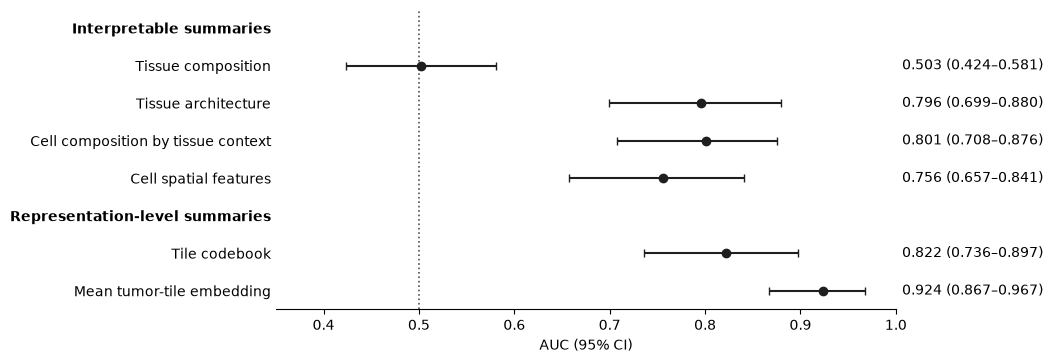

In [15]:
plot_msi_results(frozen_table("msi.csv"))  # the AUC of each feature block, with its 95% CI

<p class="figure-caption">AUC with its 95% confidence interval for each feature block, from repeated nested cross-validation in the BRAF cohort (114 patients, 35 MSI-H). The intervals resample patients within MSI status over the fixed out-of-fold predictions.</p>

Tissue composition alone is close to chance. Tissue architecture, cell-level summaries and
representation-level features carry more MSI signal in this cohort, with the mean tumor-tile
embedding giving the highest AUC.

These downstream classifiers are trained and cross-validated within BRAF. Transfer to an
independent cohort containing both MSI-H and MSS tumors is not tested.

## Take-home

- **Encode once.** ALHENA produces tile and cell representations and cell annotations that can be
  reused across tissue, cell and spatial analyses without repeatedly encoding the H&E image.
- **Stay in the scverse ecosystem.** ALHENA outputs fit naturally into AnnData and SpatialData and
  can be combined directly with tools such as Scanpy and Squidpy.
- **Move across scales and identify challenging contexts.** The same outputs support
  tissue-context analysis, spatial cell queries and patient-level features. Comparison with the
  published annotations highlights contexts in which agreement is lower, particularly in
  tumor-containing tissue around published lymphocytes with many nearby published cancer
  epithelial cells.

## Data and attribution

- Images: BioImage Archive S-BIAD1407,
  [doi:10.6019/S-BIAD1407](https://doi.org/10.6019/S-BIAD1407),
  [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- Nucleus positions and classes: Mendeley Data 9z48yfzr63,
  [doi:10.17632/9z48yfzr63.1](https://doi.org/10.17632/9z48yfzr63.1), CC BY 4.0.
- MSI status and the 44.65 µm proximity threshold: Trahearn N, et al. Computational pathology
  applied to clinical colorectal cancer cohorts identifies immune and endothelial cell spatial
  patterns predictive of outcome. J Pathol 2025;265:198–210.
  [doi:10.1002/path.6378](https://doi.org/10.1002/path.6378), CC BY 4.0.

H&E images shown on this page are cropped, downsampled, converted to grayscale or overlaid
versions of the source images.

---

**Next:** [How ALHENA works](../../concepts/how-it-works/)